<h1 align="center">E-Commerce Customer Segmentation</h1>
<h3 align="center"> Holdout Validation, Lapse Risk and Loyalty Tiers</h3> 

**Project:** E-Commerce Customer Segmentation: RFM and K-Means Analysis of Who Drives, and Who Threatens, Revenue

This notebook answers two objectives from the [analysis charter](../02_documentation/analysis_charter.md):

- **Objective 3:** *"Who is slipping away, how much revenue goes with them, and do customers get more valuable over time?"*
- **Objective 2:** *"Is our tier programme rewarding the right people?"*

The segments from Notebook 2 (RFM) and Notebook 3 (K-means) describe customers. This notebook tests whether they **predict** anything. Segments are rebuilt using only orders up to 31 Dec 2025, and then checked against what customers actually did in Jan–Jun 2026, a period the segments never saw.

**Steps**

We want to:

1. Record what every calibration customer did in Jan–Jun 2026, and check the figures against Notebook 1.
2. Refit the Notebook 3 K-means model on calibration data only.
3. Check lapse rate and revenue at risk for each segment.
4. Test which method best predicts who stops buying: K-means, RFM, raw recency, or the loyalty tier? And why does past behaviour predict so little?
5. Test whether there is a gap between orders after which customers stop coming back?
6. Test  whether customer value builds or fade with tenure? (registration cohorts)
7. Test whether the loyalty tiers match behaviour, and whether behaviour or tier better predict 2026? (Objective 2)
8. Look ahead: estimate revenue at risk in Jul–Dec 2026 and a rank win-back list, build on the signal that passed the test.

**Source tags.** Figures from earlier notebooks are tagged *[Notebook 1]*, *[Notebook 2]* or *[Notebook 3]*. Every other figure is calculated here and is cited elsewhere as *[Notebook 4]*.

| Input | Output |
|---|---|
| `01_data/processed/Fact_Sales.csv`, `Dim_Customers.csv` | `01_data/output/holdout_outcomes_calibration.csv` |
| `01_data/output/customer_features_calibration.csv`, `customer_features_full.csv` *[Notebook 1]* | `01_data/output/winback_ranked.csv` |
| `01_data/output/rfm_scores_calibration.csv`, `rfm_scores_full.csv` *[Notebook 2]* | `01_data/output/tier_upgrade_candidates.csv` |
| `01_data/output/kmeans_segments_full.csv`, `kmeans_model_config.json` *[Notebook 3]* | `01_data/output/platinum_low_activity.csv` |
| | `04_report/figures/nb04_*.png` |

### Time windows

| Window | Orders | Used for |
|---|---|---|
| Calibration | 1 Jun 2024 – 31 Dec 2025 (19 months), snapshot 31 Dec 2025 | Building the segments that are tested |
| Holdout | 1 Jan – 30 Jun 2026 (6 months) | Checking what those customers did next |
| Full period | 1 Jun 2024 – 30 Jun 2026 (25 months), snapshot 30 Jun 2026 | Tiers (Section 7) and the forward look (Section 8), which describe customers as they are now |

## 1. What calibration customers did in Jan–Jun 2026

A customer **lapsed** if they placed no order of any status in Jan–Jun 2026. This is the same definition used in Notebook 1, so the counts must match Notebook 1's Q3 exactly *[Notebook 1, Q3]*.

In [ ]:
# pathlib: build file paths that work on Windows, macOS and Linux
from pathlib import Path

# pandas: read and reshape the order and customer tables
import pandas as pd

# customer_features.py (this folder): shared order-status rules and time windows
import customer_features as cf

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_DIR = Path("../01_data/processed")
OUTPUT_DIR = Path("../01_data/output")

fact, dim_customers, _ = cf.load_data(DATA_DIR)
calib = pd.read_csv(OUTPUT_DIR / "customer_features_calibration.csv", index_col="customer_id")

holdout = fact[(fact.order_date >= cf.HOLDOUT_START) & (fact.order_date <= cf.FULL_END)]
holdout_valid = holdout[holdout.order_status.isin(cf.VALID_STATUSES)]
calib["lapsed"] = ~calib.index.isin(holdout.customer_id.unique())
calib["holdout_spend"] = holdout_valid.groupby("customer_id").total_amount.sum().reindex(calib.index).fillna(0)

n_lapsed = int(calib.lapsed.sum())
lapsed_spend = calib.loc[calib.lapsed, "monetary"].sum()
print(f"Calibration customers:                    {len(calib):,}")
print(f"  placed no order in Jan–Jun 2026:        {n_lapsed:,} ({n_lapsed / len(calib):.1%})")
print(f"  their calibration spend:                ₹{lapsed_spend / 1e6:,.1f} M ({lapsed_spend / calib.monetary.sum():.1%})")

# Continuity check against Notebook 1, Q3
assert len(calib) == 39_640 and n_lapsed == 9_074 and round(lapsed_spend / 1e6, 1) == 953.9
print("\nMatches Notebook 1, Q3.")

Calibration customers:                    39,640
  placed no order in Jan–Jun 2026:        9,074 (22.9%)
  their calibration spend:                ₹953.9 M (23.5%)

Matches NB01, Q3.


## 2. Refit the K-means model on calibration data only

The Notebook 3 model was fitted on the full period, which includes Jan–Jun 2026. Testing it against Jan–Jun 2026 would let the model see the answers. So the **same model settings** (features, scaling, k = 7, seed and naming rules, read from `kmeans_model_config.json`) are refitted on the calibration table, with Recency measured to 31 Dec 2025.

Calibration customers with no valid orders in the period are excluded, as in Notebook 2 and Notebook 3.

In [ ]:
# json: read the model settings saved by Notebook 3
import json

# numpy: logs, random sampling and array maths
import numpy as np

# scikit-learn: the same scaling and clustering steps as Notebook 3
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

config = json.loads((OUTPUT_DIR / "kmeans_model_config.json").read_text(encoding="utf-8"))
FEATURES, K, SEED = config["features"], config["k"], config["random_state"]

cal = calib[calib.frequency > 0].copy()
print(f"Calibration customers clustered: {len(cal):,} (excluded with no valid orders: {len(calib) - len(cal)})")


def model_features(table):
    # The seven Notebook 3 features, built the same way
    return pd.DataFrame({
        "recency_raw": table.recency_days,
        "log_frequency": np.log(table.frequency),
        "log_aov": np.log(table.aov),
        "coupon_rate": table.coupon_rate,
        "cod_share": table.cod_share,
        "electronics_share": table.electronics_share,
        "category_breadth": table.category_breadth,
    }, index=table.index)[FEATURES]


X_cal = StandardScaler().fit_transform(model_features(cal))
model = KMeans(n_clusters=K, n_init=config["n_init"], random_state=SEED).fit(X_cal)
cal["cluster"] = model.labels_
print(f"Settings reused from Notebook 3: k = {K}, seed = {SEED}, features = {FEATURES}")

Calibration customers clustered: 39,431 (excluded with no valid orders: 209)
Settings reused from NB03: k = 7, seed = 42, features = ['recency_raw', 'log_frequency', 'log_aov', 'coupon_rate', 'cod_share', 'electronics_share', 'category_breadth']


### Naming the calibration clusters

The Notebook 3 naming rules are applied unchanged *[Notebook 3, Section 6]*. If the calibration model finds the same kinds of customers, every rule picks a different cluster and the seven names reappear.

In [ ]:
SEGMENT_ORDER = ["Core high-value regulars", "Big-ticket Electronics buyers", "Coupon-led buyers",
                 "Frequent everyday shoppers", "Occasional light shoppers",
                 "Lapsed high-value customers", "Lapsed light buyers"]


def name_clusters(table, labels):
    # The Notebook 3 naming rules, applied in order to each cluster's profile
    p = table.groupby(labels).agg(recency=("recency_days", "median"), aov=("aov", "median"),
                                  frequency=("frequency", "median"), coupon_rate=("coupon_rate", "mean"),
                                  electronics_share=("electronics_share", "mean"))
    names = {}
    lapsed_clusters = p.recency.nlargest(2).index
    names[p.loc[lapsed_clusters, "aov"].idxmax()] = "Lapsed high-value customers"
    names[p.loc[lapsed_clusters, "aov"].idxmin()] = "Lapsed light buyers"
    remaining = [c for c in p.index if c not in lapsed_clusters]
    for name, column in [("Coupon-led buyers", "coupon_rate"), ("Big-ticket Electronics buyers", "electronics_share"),
                         ("Core high-value regulars", "aov"), ("Frequent everyday shoppers", "frequency")]:
        chosen = p.loc[remaining, column].idxmax()
        names[chosen] = name
        remaining.remove(chosen)
    names[remaining[0]] = "Occasional light shoppers"
    assert len(set(names.values())) == len(p)
    return names


cal_names = name_clusters(cal, cal.cluster)
cal["kmeans_segment"] = pd.Categorical(cal.cluster.map(cal_names), categories=SEGMENT_ORDER, ordered=True)

### Do the calibration segments look like the Notebook 3 segments?

The profiles below put the calibration segments (snapshot 31 Dec 2025) next to the Notebook 3 segments (snapshot 30 Jun 2026). The two are not expected to match exactly: the calibration period is six months shorter, so customers have fewer orders and shorter Recency.

In [ ]:
full = pd.read_csv(OUTPUT_DIR / "customer_features_full.csv", index_col="customer_id")
segments_full = pd.read_csv(OUTPUT_DIR / "kmeans_segments_full.csv", index_col="customer_id")
current = full[full.frequency > 0].copy()
current["kmeans_segment"] = pd.Categorical(segments_full.kmeans_segment.reindex(current.index),
                                           categories=SEGMENT_ORDER, ordered=True)


def segment_profile(table):
    p = table.groupby("kmeans_segment", observed=True).agg(
        customers=("monetary", "count"), recency_days=("recency_days", "median"), aov=("aov", "median"),
        coupon_rate=("coupon_rate", "mean"), electronics_share=("electronics_share", "mean"))
    p.insert(1, "share", p.customers / p.customers.sum())
    return p.drop(columns="customers")


side_by_side = pd.concat({"Notebook 3 (Jun 2026)": segment_profile(current), "Calibration (Dec 2025)": segment_profile(cal)},
                         axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
side_by_side = side_by_side[[(m, w) for m in ["share", "recency_days", "aov", "coupon_rate", "electronics_share"]
                             for w in ["Notebook 3 (Jun 2026)", "Calibration (Dec 2025)"]]]
fmt = {"share": "{:.1%}", "recency_days": "{:,.0f}", "aov": "₹{:,.0f}", "coupon_rate": "{:.1%}", "electronics_share": "{:.1%}"}
side_by_side.style.format({c: fmt[c[0]] for c in side_by_side.columns})

In [ ]:
# scikit-learn adjusted_rand_score: agreement between two groupings of the same customers
from sklearn.metrics import adjusted_rand_score

# Stability of the calibration model, tested as in Notebook 3: 50 bootstrap refits
rng = np.random.default_rng(K)
aris = []
for b in range(50):
    boot = rng.choice(len(X_cal), size=len(X_cal), replace=True)
    refit = KMeans(n_clusters=K, n_init=config["n_init"], random_state=b).fit(X_cal[boot])
    aris.append(adjusted_rand_score(model.labels_, refit.predict(X_cal)))
print(f"Calibration model stability: mean ARI {np.mean(aris):.3f}, worst {np.min(aris):.3f} (Notebook 3 full-period: 0.952, worst 0.899)")

both = cal.index.intersection(current.index)
same = (cal.loc[both, "kmeans_segment"].astype(str) == current.loc[both, "kmeans_segment"].astype(str)).mean()
print(f"Customers in both tables with the same segment name in Dec 2025 and Jun 2026: {same:.1%} of {len(both):,}")

Calibration model stability: mean ARI 0.910, worst 0.656 (NB03 full-period: 0.952, worst 0.899)
Customers in both tables with the same segment name in Dec 2025 and Jun 2026: 48.6% of 39,431


**Findings:**

- **The seven segments reappear in the calibration data.** Every naming rule picks a different cluster, so the model finds the same kinds of customers from 2024–25 data alone. Most profiles are close to Notebook 3's. For example, Core high-value regulars have a median basket of ₹25,505 against ₹27,834, and Frequent everyday shoppers ₹9,401 against ₹8,658.
- **Two segments are drawn differently.** The calibration **Coupon-led buyers** are a smaller, more extreme group: 7.0% of customers against 14.1%, with a coupon on 61.8% of orders and smaller baskets (₹9,163). The calibration **Lapsed high-value customers** are mostly Electronics buyers (70.4% Electronics share against 34.2%). With six fewer months of orders, the boundaries in this continuum sit in slightly different places.
- **The calibration model is less stable than the full model.** Its mean ARI is 0.910 (worst resample 0.656), against 0.952 (worst 0.899) for Notebook 3. It still meets the charter's 0.8 target on average.
- **Only 48.6% of customers carry the same segment name in Dec 2025 and Jun 2026.** This is not an independent test, because the two tables share 19 months of orders. It does show that a customer's segment is a description of their recent buying, not a fixed trait.

## 3. Lapse rate and revenue at risk by segment

For each segment:

- **Lapse rate** = calibration customers with no order in Jan–Jun 2026 ÷ calibration customers.
- **Lift** = segment lapse rate ÷ the average lapse rate. A lift of 2 means twice the average risk.
- **Revenue at risk** = the lapsed customers' calibration spend scaled to six months (× 6/19), the spend the business would have expected from them in Jan–Jun 2026 at their earlier pace. All customers registered by May 2024 *[Notebook 1]*, so each was a customer for the whole 19-month calibration period.

RFM segments and scores for the calibration period come from Notebook 2.

In [ ]:
CAL_MONTHS = 19
RFM_ORDER = ["Champions", "Loyal", "Recent low spenders", "Needs attention", "At risk", "About to sleep", "Hibernating"]

rfm_calib = pd.read_csv(OUTPUT_DIR / "rfm_scores_calibration.csv", index_col="customer_id")
assert rfm_calib.index.sort_values().equals(cal.index.sort_values()), "Customer list differs from Notebook 2"
cal["rfm_segment"] = pd.Categorical(rfm_calib.rfm_segment.reindex(cal.index), categories=RFM_ORDER, ordered=True)
cal["r_score"] = rfm_calib.r_score.reindex(cal.index)
cal["six_month_spend"] = cal.monetary * 6 / CAL_MONTHS

BASE_LAPSE = cal.lapsed.mean()
no_valid = calib[calib.frequency == 0]
print(f"Lapse rate, clustered customers: {BASE_LAPSE:.1%} of {len(cal):,}")
print(f"Lapse rate, the {len(no_valid)} customers with no valid calibration order: {no_valid.lapsed.mean():.1%}")


def lapse_table(by):
    t = cal.groupby(by, observed=True).agg(customers=("lapsed", "size"), lapsed=("lapsed", "sum"),
                                           lapse_rate=("lapsed", "mean"),
                                           holdout_spend_per_customer=("holdout_spend", "mean"))
    t["lift"] = t.lapse_rate / BASE_LAPSE
    t["revenue_at_risk"] = cal[cal.lapsed].groupby(by, observed=True).six_month_spend.sum()
    t["share_of_risk"] = t.revenue_at_risk / t.revenue_at_risk.sum()
    return t[["customers", "lapsed", "lapse_rate", "lift", "revenue_at_risk", "share_of_risk", "holdout_spend_per_customer"]]


LAPSE_FORMAT = {"customers": "{:,.0f}", "lapsed": "{:,.0f}", "lapse_rate": "{:.1%}", "lift": "{:.2f}",
                "revenue_at_risk": lambda v: f"₹{v / 1e6:,.1f} M", "share_of_risk": "{:.1%}",
                "holdout_spend_per_customer": "₹{:,.0f}"}
kmeans_lapse = lapse_table("kmeans_segment")
rfm_lapse = lapse_table("rfm_segment")
print(f"Total revenue at risk: ₹{kmeans_lapse.revenue_at_risk.sum() / 1e6:,.1f} M over six months")
display(kmeans_lapse.style.format(LAPSE_FORMAT))
display(rfm_lapse.style.format(LAPSE_FORMAT))

Lapse rate, clustered customers: 22.9% of 39,431
Lapse rate, the 209 customers with no valid calibration order: 22.5%
Total revenue at risk: ₹301.2 M over six months


,customers,lapsed,lapse_rate,lift,revenue_at_risk,share_of_risk,holdout_spend_per_customer
kmeans_segment,,,,,,,
Core high-value regulars,"12,596","2,980",23.7%,1.03,₹155.7 M,51.7%,"₹35,795"
Big-ticket Electronics buyers,"6,204","1,427",23.0%,1.00,₹75.5 M,25.1%,"₹37,935"
Coupon-led buyers,"2,769",631,22.8%,1.00,₹6.8 M,2.2%,"₹28,384"
Frequent everyday shoppers,"6,167","1,368",22.2%,0.97,₹24.9 M,8.3%,"₹21,820"
Occasional light shoppers,"6,038","1,358",22.5%,0.98,₹14.0 M,4.7%,"₹28,630"
Lapsed high-value customers,"2,705",612,22.6%,0.99,₹21.8 M,7.2%,"₹36,904"
Lapsed light buyers,"2,952",651,22.1%,0.96,₹2.5 M,0.8%,"₹28,457"


,customers,lapsed,lapse_rate,lift,revenue_at_risk,share_of_risk,holdout_spend_per_customer
rfm_segment,,,,,,,
Champions,"7,321","1,705",23.3%,1.02,₹101.8 M,33.8%,"₹33,039"
Loyal,"9,169","2,153",23.5%,1.03,₹86.2 M,28.6%,"₹32,736"
Recent low spenders,"4,487",994,22.2%,0.97,₹9.5 M,3.2%,"₹28,929"
Needs attention,"2,687",608,22.6%,0.99,₹5.6 M,1.9%,"₹29,286"
At risk,"3,500",834,23.8%,1.04,₹49.7 M,16.5%,"₹37,082"
About to sleep,"3,930",877,22.3%,0.97,₹30.9 M,10.3%,"₹32,301"
Hibernating,"8,337","1,856",22.3%,0.97,₹17.4 M,5.8%,"₹29,846"


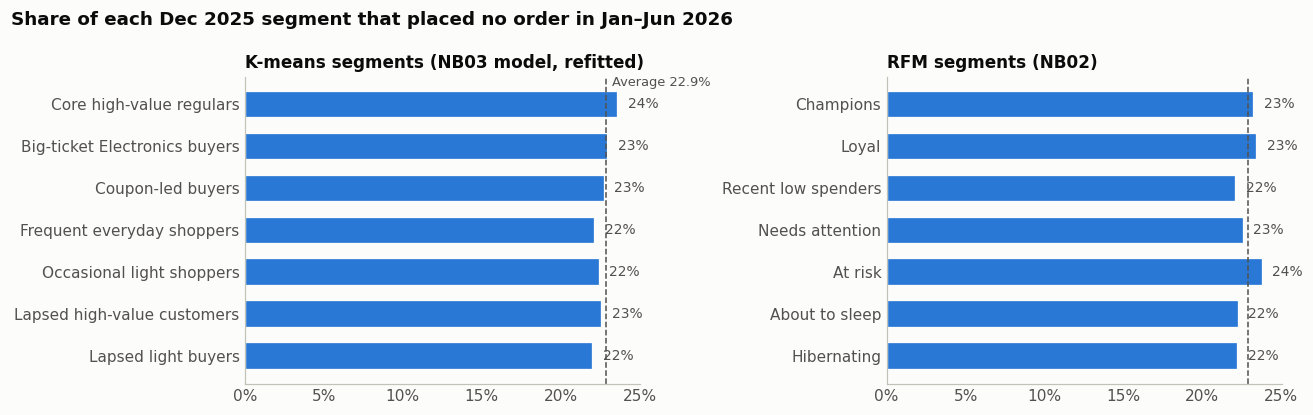

In [ ]:
# matplotlib: draw the charts; FuncFormatter formats axis numbers
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# plot_style.py (this folder): shared colours and chart defaults for every notebook
import plot_style as ps
ps.apply()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, table, title in [(axes[0], kmeans_lapse, "K-means segments (Notebook 3 model, refitted)"),
                         (axes[1], rfm_lapse, "RFM segments (Notebook 2)")]:
    rates = table.lapse_rate[::-1]
    ax.barh(rates.index.astype(str), rates.values, height=0.65, **ps.bar_kwargs())
    for y, v in enumerate(rates.values):
        ax.text(v + 0.006, y, f"{v:.0%}", va="center", fontsize=9, color=ps.TEXT_SECONDARY)
    ax.axvline(BASE_LAPSE, color=ps.TEXT_SECONDARY, linewidth=1, linestyle="--")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[0].annotate(f"Average {BASE_LAPSE:.1%}", xy=(BASE_LAPSE, 6.45), xytext=(4, 0), textcoords="offset points",
                 fontsize=8.5, color=ps.TEXT_SECONDARY)
fig.suptitle("Share of each Dec 2025 segment that placed no order in Jan–Jun 2026", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
ps.save(fig, "nb04_lapse_by_segment")
plt.show()

**Finding: every segment lapsed at almost exactly the same rate.**

- **K-means segments:** lapse rates of 22.1%–23.7%, with lifts of 0.96–1.03. The two "Lapsed" segments lapsed no more often than Core high-value regulars.
- **RFM segments:** 22.2%–23.8%. Notebook 2's At risk customers lapsed at 23.8%, and Champions at 23.3%.

Revenue at risk (₹301.2 M over six months) therefore follows **value, not risk**. Core high-value regulars hold 51.7% of it and Big-ticket Electronics buyers 25.1%, because that is where the spend is.

This contradicts the charter's hypothesis that segments with low Recency or falling Frequency at the end of 2025 would account for most of the customers who stopped buying. Sections 4 and 4.1 test how general this is and why it happens.

## 4. Which method best predicts who stops buying?

Each method is turned into a score per customer and judged by the **area under the ROC curve (AUC)**: the chance that a randomly chosen customer who lapsed scores as higher risk than a randomly chosen customer who stayed. 0.5 is no better than a coin toss and 1.0 is perfect.

| Score | How it is built |
|---|---|
| Days since last order | Raw Recency at 31 Dec 2025. The simplest possible rule |
| RFM Recency score | Notebook 2's 1–5 Recency score, reversed so that 1 is highest risk |
| RFM segment | The segment's lapse rate |
| K-means segment | The segment's lapse rate |
| K-means segment × Recency score | The lapse rate of the customer's segment-and-score combination (7 × 5 = 35 groups). This is the combination Notebook 3 proposed for the playbook *[Notebook 3, Section 7]* |
| Loyalty tier | The tier's lapse rate. Tier is not a segmentation method, but it is the label the business already uses, so it is the benchmark any segmentation should beat |
| Loyalty tier × K-means segment | The lapse rate of the customer's tier-and-segment combination (3 × 7 = 21 groups) |
| Loyalty tier × RFM segment | The same, with the RFM segment (21 groups) |

Scores built from a group's lapse rate are **cross-fitted**: customers are split into five folds, and each fold is scored with lapse rates measured on the other four. No customer is scored using their own outcome. A 95% confidence interval for each AUC comes from 200 bootstrap resamples of customers.

In [8]:
# scikit-learn: the AUC measure and the five-fold split
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

y = cal.lapsed.astype(int).to_numpy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(cal, y))


def cross_fitted_rate(groups):
    groups = pd.Series(groups).astype(str).to_numpy()
    score = np.empty(len(groups))
    for train, test in folds:
        rates = pd.Series(y[train]).groupby(groups[train]).mean()
        score[test] = pd.Series(groups[test]).map(rates).fillna(y[train].mean()).to_numpy()
    return score


scores = {
    "Days since last order": cal.recency_days.to_numpy(),
    "RFM Recency score": -cal.r_score.to_numpy(),
    "RFM segment": cross_fitted_rate(cal.rfm_segment),
    "K-means segment": cross_fitted_rate(cal.kmeans_segment),
    "K-means segment × Recency score": cross_fitted_rate(cal.kmeans_segment.astype(str) + " | " + cal.r_score.astype(str)),
    "Loyalty tier": cross_fitted_rate(cal.customer_tier),
    "Loyalty tier × K-means segment": cross_fitted_rate(cal.customer_tier + " | " + cal.kmeans_segment.astype(str)),
    "Loyalty tier × RFM segment": cross_fitted_rate(cal.customer_tier + " | " + cal.rfm_segment.astype(str)),
}

boot_rng = np.random.default_rng(SEED)
boot_idx = [boot_rng.choice(len(y), size=len(y), replace=True) for _ in range(200)]
rows = []
for name, s in scores.items():
    boot = np.array([roc_auc_score(y[i], s[i]) for i in boot_idx])
    ref = np.array([roc_auc_score(y[i], scores["Days since last order"][i]) for i in boot_idx])
    rows.append({"score": name, "auc": roc_auc_score(y, s),
                 "ci_low": np.percentile(boot, 2.5), "ci_high": np.percentile(boot, 97.5),
                 "vs_days_low": np.percentile(boot - ref, 2.5), "vs_days_high": np.percentile(boot - ref, 97.5)})
auc_table = pd.DataFrame(rows).set_index("score").sort_values("auc", ascending=False)
auc_table.style.format("{:.3f}")

,auc,ci_low,ci_high,vs_days_low,vs_days_high
score,,,,,
Loyalty tier × K-means segment,0.606,0.600,0.612,0.100,0.120
Loyalty tier × RFM segment,0.604,0.598,0.610,0.099,0.118
Loyalty tier,0.570,0.564,0.577,0.067,0.085
K-means segment,0.502,0.494,0.509,-0.005,0.017
RFM segment,0.502,0.495,0.508,-0.004,0.018
RFM Recency score,0.495,0.489,0.503,-0.001,0.002
K-means segment × Recency score,0.495,0.488,0.501,-0.011,0.010
Days since last order,0.495,0.488,0.501,0.000,0.000


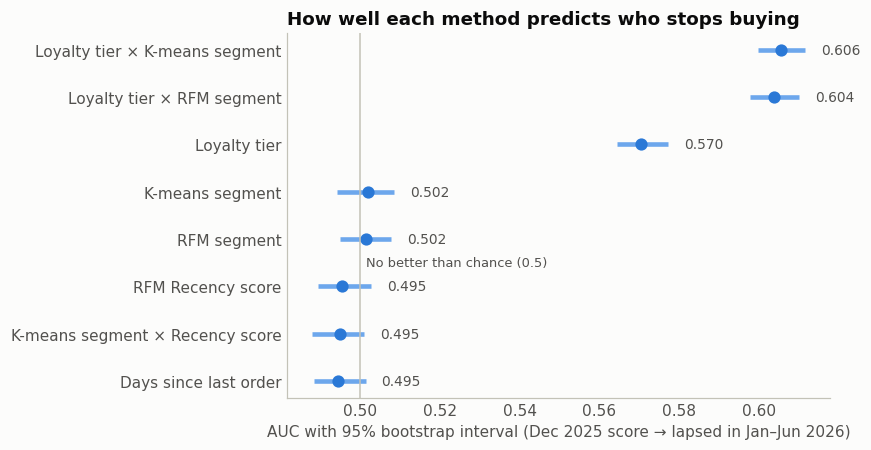

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
t = auc_table[::-1]
ax.hlines(range(len(t)), t.ci_low, t.ci_high, color=ps.BLUE_RAMP[2], linewidth=3)
ax.plot(t.auc, range(len(t)), "o", color=ps.SERIES[0], markersize=7)
for i, (v, hi) in enumerate(zip(t.auc, t.ci_high)):
    ax.text(hi + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color=ps.TEXT_SECONDARY)
ax.set_yticks(range(len(t)), t.index)
ax.axvline(0.5, color=ps.BASELINE, linewidth=1)
ax.annotate("No better than chance (0.5)", xy=(0.5, 2.5), xytext=(4, 0), textcoords="offset points",
            va="center", fontsize=8.5, color=ps.TEXT_SECONDARY)
ax.set_xlabel("AUC with 95% bootstrap interval (Dec 2025 score → lapsed in Jan–Jun 2026)")
ax.grid(axis="y", visible=False)
ax.set_title("How well each method predicts who stops buying", loc="left")
fig.tight_layout()
ps.save(fig, "nb04_auc_comparison")
plt.show()

**Finding: no behavioural score predicts who stopped buying; tier does.**

- **Days since last order, the RFM Recency score, the RFM segment and the K-means segment all score 0.495–0.502**, and every 95% interval includes 0.5. On this data, they are no better than chance.
- **Combining the K-means segment with the Recency score does not help** (0.495). The combination NB03 proposed for the playbook has no predictive value for lapse.
- **The loyalty tier is the only single score that works** (0.570, interval 0.564–0.577).
- **Tier combined with a segment does best:** 0.606 with the K-means segment and 0.604 with the RFM segment. That is about 0.11 above days since last order (interval 0.100–0.120). The segment adds information *only once tier is known*. Section 4.1 shows that, within a tier, it often points in the opposite direction to what the segment name suggests.

An AUC of 0.6 is modest: a useful ranking for prioritising contact, not a reliable way to identify individual customers who will leave.

### 4.1 Why does past behaviour predict so little?

Three checks explain the result:

1. **Is the overall lapse rate what random ordering would produce?** If each customer's orders simply arrived at random at the average pace, the share with no order in six months would follow from the average number of orders per customer in that period (a Poisson process: the chance of zero orders is e<sup>−mean</sup>).
2. **Do customers who ordered more in 2024–25 order more in 2026?** Rank correlation between calibration orders and holdout orders, for all customers and within each tier.
3. **How do lapse rate and 2026 spend vary by tier and segment together?**

In [10]:
holdout_orders = holdout.groupby("customer_id").size().reindex(cal.index).fillna(0)
mean_orders = holdout_orders.mean()
print(f"Average orders per calibration customer in Jan–Jun 2026: {mean_orders:.2f}")
print(f"Share with no order if orders arrived at random at that pace (e^-{mean_orders:.2f}): {np.exp(-mean_orders):.1%}")
print(f"Share with no order, observed: {BASE_LAPSE:.1%}")

# scipy spearmanr: rank correlation, which does not assume a straight-line relationship
from scipy.stats import spearmanr

TIER_ORDER = ["Silver", "Gold", "Platinum"]
persistence = [{"group": "All customers", "customers": len(cal),
                "orders_rho": spearmanr(cal.orders_placed, holdout_orders)[0],
                "spend_rho": spearmanr(cal.monetary, cal.holdout_spend)[0]}]
for tier in TIER_ORDER:
    g = cal[cal.customer_tier == tier]
    persistence.append({"group": tier, "customers": len(g),
                        "orders_rho": spearmanr(g.orders_placed, holdout_orders[g.index])[0],
                        "spend_rho": spearmanr(g.monetary, g.holdout_spend)[0]})
persistence = pd.DataFrame(persistence).set_index("group")
persistence.columns = ["customers", "ρ: calibration orders vs 2026 orders", "ρ: calibration spend vs 2026 spend"]
persistence.style.format({"customers": "{:,.0f}", "ρ: calibration orders vs 2026 orders": "{:+.3f}",
                          "ρ: calibration spend vs 2026 spend": "{:+.3f}"})

Average orders per calibration customer in Jan–Jun 2026: 1.48
Share with no order if orders arrived at random at that pace (e^-1.48): 22.7%
Share with no order, observed: 22.9%


,customers,ρ: calibration orders vs 2026 orders,ρ: calibration spend vs 2026 spend
group,,,
All customers,"39,431",+0.002,+0.066
Silver,"5,586",-0.002,-0.101
Gold,"6,604",-0.057,-0.474
Platinum,"27,241",-0.070,-0.198


In [11]:
by_tier = cal.groupby(pd.Categorical(cal.customer_tier, categories=TIER_ORDER, ordered=True), observed=True).agg(
    customers=("lapsed", "size"), calibration_orders=("orders_placed", "mean"), lapse_rate=("lapsed", "mean"),
    holdout_spend_per_customer=("holdout_spend", "mean"))
by_tier.index.name = "customer_tier"
display(by_tier.style.format({"customers": "{:,.0f}", "calibration_orders": "{:.2f}", "lapse_rate": "{:.1%}",
                              "holdout_spend_per_customer": "₹{:,.0f}"}))

tier_seg_lapse = pd.crosstab(cal.kmeans_segment, cal.customer_tier, values=cal.lapsed, aggfunc="mean")[TIER_ORDER]
tier_seg_spend = pd.crosstab(cal.kmeans_segment, cal.customer_tier, values=cal.holdout_spend, aggfunc="mean")[TIER_ORDER]
tier_seg_n = pd.crosstab(cal.kmeans_segment, cal.customer_tier)[TIER_ORDER]
display(pd.concat({"lapse_rate": tier_seg_lapse, "holdout_spend_per_customer": tier_seg_spend, "customers": tier_seg_n},
                  axis=1).style.format({**{("lapse_rate", t): "{:.1%}" for t in TIER_ORDER},
                                        **{("holdout_spend_per_customer", t): "₹{:,.0f}" for t in TIER_ORDER},
                                        **{("customers", t): "{:,.0f}" for t in TIER_ORDER}}))

,customers,calibration_orders,lapse_rate,holdout_spend_per_customer
customer_tier,,,,
Silver,"5,586",3.43,36.0%,"₹4,737"
Gold,"6,604",4.26,26.0%,"₹10,974"
Platinum,"27,241",5.25,19.5%,"₹42,478"


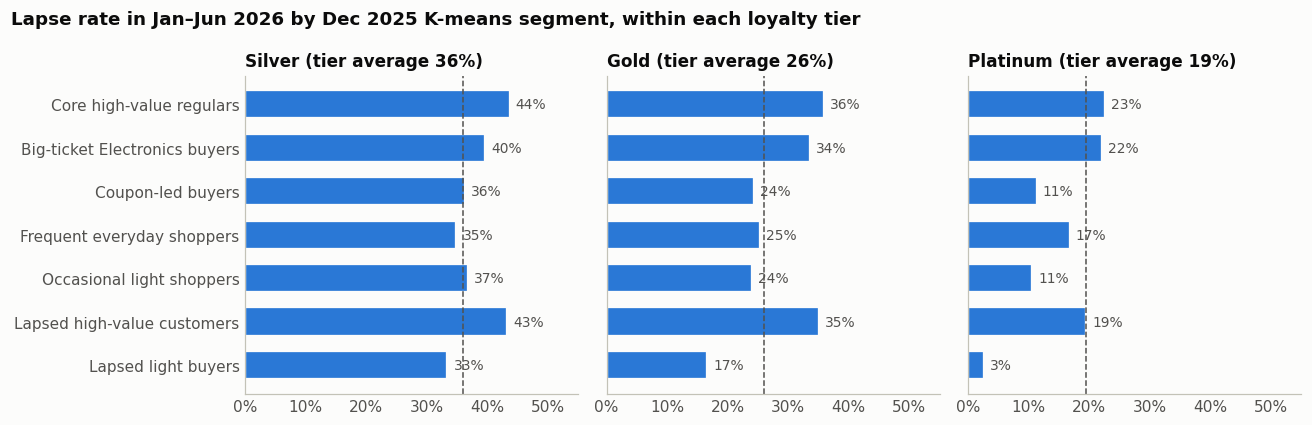

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
for ax, tier in zip(axes, TIER_ORDER):
    rates = tier_seg_lapse[tier][::-1]
    ax.barh(rates.index.astype(str), rates.values, height=0.65, **ps.bar_kwargs())
    for yy, v in enumerate(rates.values):
        ax.text(v + 0.01, yy, f"{v:.0%}", va="center", fontsize=9, color=ps.TEXT_SECONDARY)
    ax.axvline(by_tier.loc[tier, "lapse_rate"], color=ps.TEXT_SECONDARY, linewidth=1, linestyle="--")
    ax.set_title(f"{tier} (tier average {by_tier.loc[tier, 'lapse_rate']:.0%})", fontsize=11)
    ax.set_xlim(0, 0.55)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.suptitle("Lapse rate in Jan–Jun 2026 by Dec 2025 K-means segment, within each loyalty tier", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
ps.save(fig, "nb04_lapse_by_tier_and_segment")
plt.show()

**Findings:**

1. **The overall lapse rate is what random ordering would produce.** Calibration customers placed an average of 1.48 orders in Jan–Jun 2026. If orders simply arrived at random at that pace, 22.7% would place none; the observed figure is 22.9%.
2. **Past ordering does not carry forward.** Across all customers, the rank correlation between 2024–25 orders and 2026 orders is +0.002. **Within each tier it is slightly negative** (−0.002 Silver, −0.057 Gold, −0.070 Platinum), and spend is more strongly negative (down to −0.474 for Gold). Customers who bought more than their tier's typical amount in 2024–25 bought *less* in 2026, and the reverse.
3. **Tier sets the level.**
   - Silver customers lapsed at 36.0% and spent ₹4,737 each in Jan–Jun 2026.
   - Gold customers lapsed at 26.0% and spent ₹10,974.
   - Platinum customers lapsed at 19.5% and spent ₹42,478.
4. **Within a tier, the "weakest-looking" segments lapsed least.** Among Platinum customers, Lapsed light buyers (697 customers) lapsed at only 2.6% and spent ₹89,683 each in 2026, the most of any group. Occasional light shoppers (10.6%) and Coupon-led buyers (11.3%) also did better than Core high-value regulars (22.6%). The same pattern appears in Gold.

**What this means.** The pattern fits data where each customer's tier sets how much they buy over the two years, and the timing of individual orders is otherwise random. A customer who bought little in 2024–25 still has their "share" to come, so they catch up. The first project already noted that the data is likely synthetic *[Report §5]*, and this is the clearest sign of it so far. For a real retailer the same test would very likely show recency mattering. The professional point stands either way: **segments must be tested against later behaviour before they drive retention spending**, because here the intuitive rules would have targeted the wrong customers.

## 5. Is there a gap after which customers stop coming back?

Two views, as the charter set out:

1. **Normal gaps between orders.** For every customer, the days between consecutive order dates (all statuses, calibration period only, so no holdout information is used). The charter proposed the 90th percentile as a practical "lapsed" threshold.
2. **Lapse rate by days since last order** at 31 Dec 2025, in 30-day bands. If the threshold is meaningful, customers beyond it should lapse more often in Jan–Jun 2026.

Gaps are only measured between orders that happened, so very long gaps still in progress at the snapshot are not counted. The 90th percentile is therefore a conservative (short) threshold.

In [13]:
order_days = (fact.loc[fact.order_date <= cf.CALIBRATION_END, ["customer_id", "order_date"]]
              .drop_duplicates().sort_values(["customer_id", "order_date"]))
gaps = order_days.groupby("customer_id").order_date.diff().dt.days.dropna()
GAP_THRESHOLD = int(np.ceil(gaps.quantile(0.90)))
print(f"Gaps between consecutive order dates (calibration): {len(gaps):,}")
print(gaps.quantile([0.25, 0.5, 0.75, 0.9, 0.95]).rename("days").to_frame().T.to_string())
print(f"\n90th percentile gap: {GAP_THRESHOLD} days")

cal["recency_band"] = pd.cut(cal.recency_days, bins=range(0, int(cal.recency_days.max()) + 31, 30), right=False)
by_band = cal.groupby("recency_band", observed=True).agg(customers=("lapsed", "size"), lapse_rate=("lapsed", "mean"))
cal["past_threshold"] = cal.recency_days > GAP_THRESHOLD
threshold_split = cal.groupby("past_threshold").agg(customers=("lapsed", "size"), lapse_rate=("lapsed", "mean"),
                                                    revenue_at_risk=("six_month_spend", lambda s: s[cal.loc[s.index, "lapsed"]].sum()))
threshold_split.index = [f"Ordered within {GAP_THRESHOLD} days", f"No order for more than {GAP_THRESHOLD} days"]
threshold_split.style.format({"customers": "{:,.0f}", "lapse_rate": "{:.1%}", "revenue_at_risk": lambda v: f"₹{v / 1e6:,.1f} M"})

Gaps between consecutive order dates (calibration): 150,253
      0.250  0.500   0.750   0.900   0.950
days 28.000 66.000 129.000 209.000 265.000

90th percentile gap: 209 days


,customers,lapse_rate,revenue_at_risk
Ordered within 209 days,"32,868",23.1%,₹268.4 M
No order for more than 209 days,"6,563",22.0%,₹32.8 M


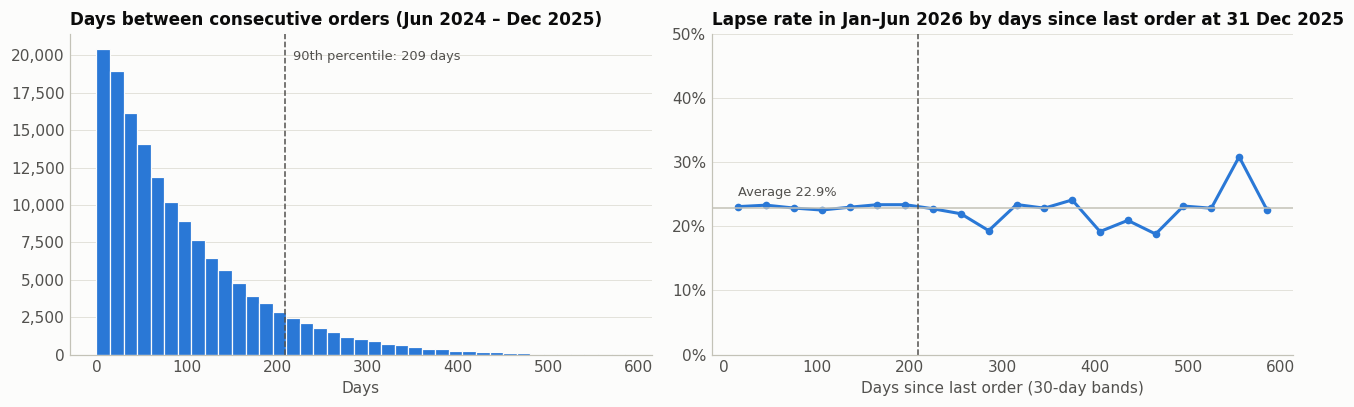

recency_band,"[0, 30)","[30, 60)","[60, 90)","[90, 120)","[120, 150)","[150, 180)","[180, 210)","[210, 240)","[240, 270)","[270, 300)","[300, 330)","[330, 360)","[360, 390)","[390, 420)","[420, 450)","[450, 480)","[480, 510)","[510, 540)","[540, 570)","[570, 600)"
customers,"8,763.00","6,777.00","5,424.00","4,106.00","3,227.00","2,523.00","2,048.00","1,587.00","1,115.00",905.00,726.00,591.00,431.00,323.00,277.00,218.00,151.00,127.00,81.00,31.00
lapse_rate,0.23,0.23,0.23,0.23,0.23,0.23,0.23,0.23,0.22,0.19,0.23,0.23,0.24,0.19,0.21,0.19,0.23,0.23,0.31,0.23


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

ax = axes[0]
ax.hist(gaps, bins=range(0, int(gaps.max()) + 15, 15), color=ps.SERIES[0], edgecolor=ps.SURFACE, linewidth=0.8)
ax.axvline(GAP_THRESHOLD, color=ps.TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.annotate(f"90th percentile: {GAP_THRESHOLD} days", xy=(GAP_THRESHOLD, ax.get_ylim()[1] * 0.92), xytext=(5, 0),
            textcoords="offset points", fontsize=8.5, color=ps.TEXT_SECONDARY)
ax.set_title("Days between consecutive orders (Jun 2024 – Dec 2025)", fontsize=11)
ax.set_xlabel("Days")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

ax = axes[1]
mid = [b.left + 15 for b in by_band.index]
ax.plot(mid, by_band.lapse_rate, color=ps.SERIES[0], marker="o", markersize=4)
ax.axhline(BASE_LAPSE, color=ps.BASELINE, linewidth=1)
ax.axvline(GAP_THRESHOLD, color=ps.TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.annotate(f"Average {BASE_LAPSE:.1%}", xy=(mid[0], BASE_LAPSE), xytext=(0, 8), textcoords="offset points",
            fontsize=8.5, color=ps.TEXT_SECONDARY)
ax.set_title("Lapse rate in Jan–Jun 2026 by days since last order at 31 Dec 2025", fontsize=11)
ax.set_xlabel("Days since last order (30-day bands)")
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.tight_layout()
ps.save(fig, "nb04_lapse_by_recency")
plt.show()
by_band.T.style.format("{:,.2f}")

**Findings:**

- **Normal gaps between orders:** a median of 66 days, with 75% under 129 days and 90% under **209 days** (95% under 265).
- **The 209-day threshold does not mark a lapse.** Customers past it lapsed at 22.0%, against 23.1% for those within it. Across 30-day bands, the lapse rate stays between 19% and 24% from 0 to 540 days. The one higher point (31% at 540–570 days) rests on only 81 customers.

**Implication:** in this data, no gap length signals that a customer is leaving, so "how early to step in" has no answer based on recency. The 209-day figure stays useful as a description of normal buying rhythm. It is not used as a trigger in the playbook.

## 6. Does customer value build or fade with tenure?

This answers the first project's deferred **Q7** (customer value by tenure and cohort). Customers are grouped by **registration month**: 12 cohorts from Jun 2023 to May 2024 *[Notebook 1]*. For each cohort and calendar month, spend is divided by the number of customers who **registered** in that cohort (not just those who bought), so a cohort that loses buyers shows falling spend.

**A limit of this data.** Every customer registered within the same 12 months, and every order falls in the same 25-month window. A cohort's tenure therefore rises in step with the calendar, and tenure, calendar time and cohort cannot be fully separated. Two comparisons are used instead:

- **Same month, different tenure:** within each calendar month, do older cohorts spend more or less per customer than newer ones?
- **Same cohort over time:** does each cohort's spend per customer rise or fall from month to month?

Cohorts: 12 (2023-06 to 2024-05), 40,000 registered customers, 3,219–3,401 per cohort


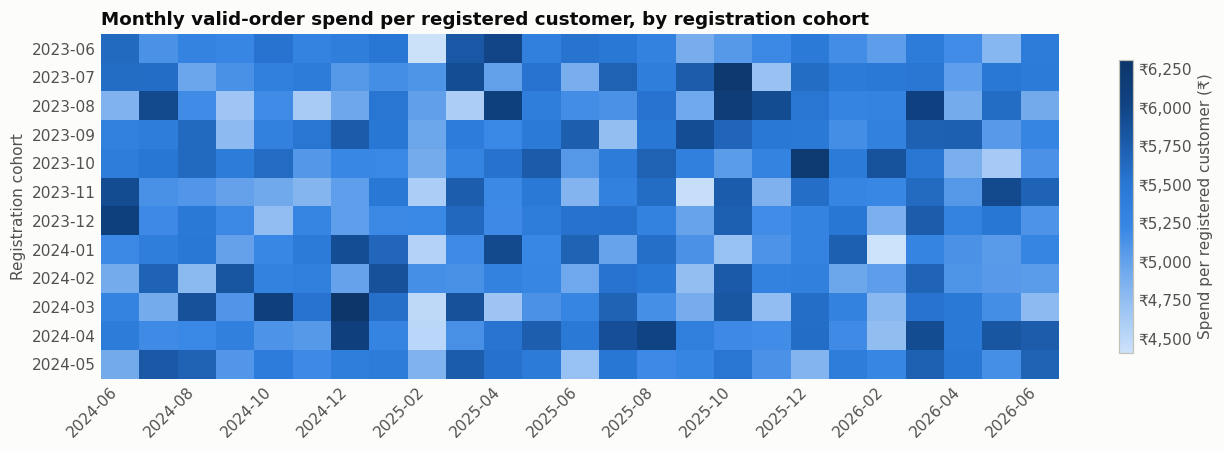

In [15]:
valid = fact[fact.order_status.isin(cf.VALID_STATUSES)].copy()
valid["order_month"] = valid.order_date.dt.to_period("M")
valid["cohort"] = valid.registration_date.dt.to_period("M")
cohort_size = dim_customers.registration_date.dt.to_period("M").value_counts().sort_index()

spend = valid.groupby(["cohort", "order_month"]).total_amount.sum().unstack()
spend_per_customer = spend.div(cohort_size, axis=0)
print(f"Cohorts: {len(cohort_size)} ({cohort_size.index.min()} to {cohort_size.index.max()}), "
      f"{cohort_size.sum():,} registered customers, {cohort_size.min():,}–{cohort_size.max():,} per cohort")

# LinearSegmentedColormap: turn the project's blue ramp into a continuous colour scale
from matplotlib.colors import LinearSegmentedColormap
BLUES = LinearSegmentedColormap.from_list("project_blues", ps.BLUE_RAMP)

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(spend_per_customer.values, cmap=BLUES, aspect="auto")
ax.set_yticks(range(len(spend_per_customer)), [str(c) for c in spend_per_customer.index])
ax.set_xticks(range(0, spend_per_customer.shape[1], 2), [str(m) for m in spend_per_customer.columns[::2]],
              rotation=45, ha="right")
ax.set_ylabel("Registration cohort")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.85, label="Spend per registered customer (₹)",
             format=FuncFormatter(lambda x, _: f"₹{x:,.0f}"))
ax.set_title("Monthly valid-order spend per registered customer, by registration cohort", loc="left")
fig.tight_layout()
ps.save(fig, "nb04_cohort_heatmap")
plt.show()

In [16]:
panel = spend_per_customer.stack().rename("spend_per_customer").reset_index()
panel["tenure_months"] = [(m - c).n for c, m in zip(panel.cohort, panel.order_month)]

# Same month, different tenure: correlation between tenure and spend across the 12 cohorts, month by month
within_month = panel.groupby("order_month").apply(
    lambda g: spearmanr(g.tenure_months, g.spend_per_customer)[0], include_groups=False)
# Same cohort over time: correlation between calendar month and spend, cohort by cohort
within_cohort = panel.groupby("cohort").apply(
    lambda g: spearmanr(g.order_month.map(lambda p: p.ordinal), g.spend_per_customer)[0], include_groups=False)

print(f"Same month, older vs newer cohorts: median ρ = {within_month.median():+.2f}, "
      f"positive in {(within_month > 0).sum()} of {len(within_month)} months")
print(f"Same cohort over time:              median ρ = {within_cohort.median():+.2f}, "
      f"positive in {(within_cohort > 0).sum()} of {len(within_cohort)} cohorts")

# Each cohort: spend per registered customer in its first and last six full months of data, and its holdout lapse rate
early = spend_per_customer.loc[:, pd.Period("2024-07", "M"):pd.Period("2024-12", "M")].sum(axis=1)
late = spend_per_customer.loc[:, pd.Period("2026-01", "M"):pd.Period("2026-06", "M")].sum(axis=1)
cohort_table = pd.DataFrame({
    "registered": cohort_size,
    "spend_per_customer_jul_dec_2024": early,
    "spend_per_customer_jan_jun_2026": late,
    "change": late / early - 1,
    "calibration_lapse_rate": calib.groupby(pd.PeriodIndex(calib.registration_cohort, freq="M")).lapsed.mean(),
})
cohort_table.index.name = "cohort"
cohort_table.style.format({"registered": "{:,.0f}", "spend_per_customer_jul_dec_2024": "₹{:,.0f}",
                           "spend_per_customer_jan_jun_2026": "₹{:,.0f}", "change": "{:+.1%}",
                           "calibration_lapse_rate": "{:.1%}"})

Same month, older vs newer cohorts: median ρ = +0.04, positive in 14 of 25 months
Same cohort over time:              median ρ = +0.04, positive in 7 of 12 cohorts


,registered,spend_per_customer_jul_dec_2024,spend_per_customer_jan_jun_2026,change,calibration_lapse_rate
cohort,,,,,
2023-06,"3,370","₹31,862","₹31,005",-2.7%,21.9%
2023-07,"3,378","₹31,548","₹32,365",+2.6%,24.0%
2023-08,"3,401","₹30,570","₹32,042",+4.8%,22.7%
2023-09,"3,291","₹32,423","₹32,237",-0.6%,22.9%
2023-10,"3,383","₹32,460","₹31,449",-3.1%,23.7%
2023-11,"3,330","₹30,026","₹32,829",+9.3%,23.4%
2023-12,"3,296","₹30,909","₹32,029",+3.6%,23.6%
2024-01,"3,349","₹32,418","₹30,834",-4.9%,23.2%
2024-02,"3,219","₹31,970","₹30,900",-3.3%,22.8%


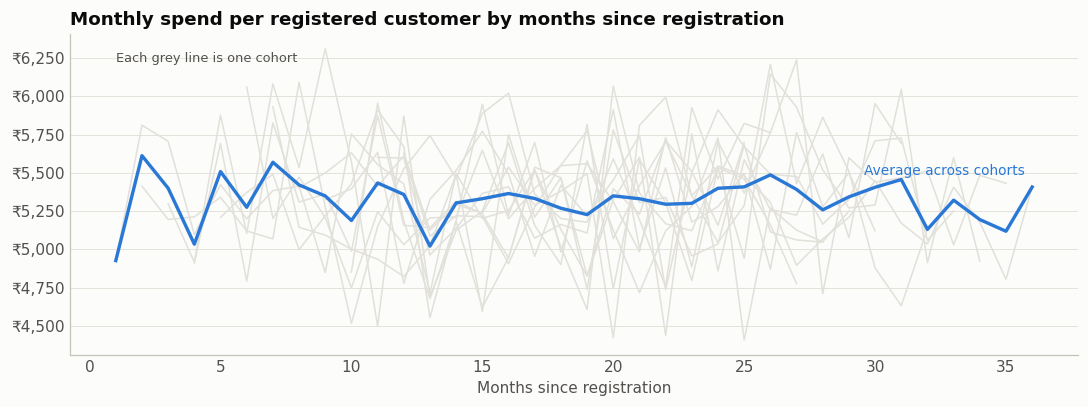

In [17]:
by_tenure = panel.pivot(index="tenure_months", columns="cohort", values="spend_per_customer")
fig, ax = plt.subplots(figsize=(10, 3.8))
for c in by_tenure.columns:
    ax.plot(by_tenure.index, by_tenure[c], color=ps.GRID, linewidth=1)
ax.plot(by_tenure.index, by_tenure.mean(axis=1), color=ps.SERIES[0], linewidth=2.2)
ax.annotate("Average across cohorts", xy=(by_tenure.index[-1], by_tenure.mean(axis=1).iloc[-1]), xytext=(-5, 8),
            textcoords="offset points", ha="right", fontsize=9, color=ps.SERIES[0])
ax.annotate("Each grey line is one cohort", xy=(by_tenure.index[0], by_tenure.max().max()), xytext=(0, -2),
            textcoords="offset points", fontsize=8.5, color=ps.TEXT_SECONDARY, va="top")
ax.set_xlabel("Months since registration")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"₹{x:,.0f}"))
ax.set_title("Monthly spend per registered customer by months since registration", loc="left")
fig.tight_layout()
ps.save(fig, "nb04_tenure_curve")
plt.show()

**Finding: customer value neither builds nor fades with tenure.**

- **Same month, different tenure:** the median rank correlation between tenure and spend per registered customer is +0.04. Older cohorts spent more than newer ones in 14 of 25 months, about what chance would give.
- **Same cohort over time:** median +0.04; spend rose over time in 7 of 12 cohorts.
- **First six months against last six months:** spend per registered customer changed by between −8.2% and +9.3% across cohorts (Jul–Dec 2024 against Jan–Jun 2026), with no pattern by cohort age.
- **Lapse rates by cohort** range only from 21.9% to 24.0%.

The heatmap and the tenure curve show month-to-month noise around a flat level, about ₹4,500–₹6,300 per registered customer per month. This matches the first project's finding that monthly revenue was flat over two years *[Report §3.1]*. It answers the deferred Q7: **long-standing customers are not more valuable than newer ones in this data**, so tenure does not justify different treatment.

## 7. Do the loyalty tiers match behaviour? (Objective 2)

Tiers describe customers **now**, so this section uses the full-period table (snapshot 30 Jun 2026) and the NB03 segments. Tier is assigned by the business and is partly based on spend *[First project README, *Notes on scope*]*; it was never used to build the segments, so comparing the two is not circular.

### Tier against segment

In [18]:
rfm_full = pd.read_csv(OUTPUT_DIR / "rfm_scores_full.csv", index_col="customer_id")
current["rfm_segment"] = pd.Categorical(rfm_full.rfm_segment.reindex(current.index), categories=RFM_ORDER, ordered=True)
current["r_score"] = rfm_full.r_score.reindex(current.index)
current["customer_tier"] = pd.Categorical(current.customer_tier, categories=TIER_ORDER, ordered=True)

tier_counts = pd.crosstab(current.kmeans_segment, current.customer_tier, margins=True, margins_name="All")
tier_revenue = pd.crosstab(current.kmeans_segment, current.customer_tier, values=current.monetary, aggfunc="sum",
                           margins=True, margins_name="All")
display(tier_counts.style.format("{:,.0f}"))
display((tier_revenue / 1e6).style.format("₹{:,.1f} M"))

customer_tier,Silver,Gold,Platinum,All
kmeans_segment,,,,
Core high-value regulars,100,416,"10,614","11,130"
Big-ticket Electronics buyers,201,357,"4,510","5,068"
Coupon-led buyers,174,610,"4,842","5,626"
Frequent everyday shoppers,"1,095","2,368","3,343","6,806"
Occasional light shoppers,"2,338","2,045","1,659","6,042"
Lapsed high-value customers,222,599,"2,356","3,177"
Lapsed light buyers,"1,677",297,25,"1,999"
All,"5,807","6,692","27,349","39,848"


customer_tier,Silver,Gold,Platinum,All
kmeans_segment,,,,
Core high-value regulars,₹10.4 M,₹36.9 M,"₹2,330.5 M","₹2,377.7 M"
Big-ticket Electronics buyers,₹13.5 M,₹23.9 M,₹904.2 M,₹941.7 M
Coupon-led buyers,₹10.3 M,₹37.5 M,₹859.1 M,₹906.9 M
Frequent everyday shoppers,₹25.9 M,₹99.6 M,₹323.5 M,₹449.0 M
Occasional light shoppers,₹34.4 M,₹78.1 M,₹140.1 M,₹252.6 M
Lapsed high-value customers,₹12.9 M,₹30.8 M,₹334.4 M,₹378.0 M
Lapsed light buyers,₹11.8 M,₹8.8 M,₹1.6 M,₹22.2 M
All,₹119.1 M,₹315.5 M,"₹4,893.5 M","₹5,328.1 M"


In [19]:
# scipy chi2_contingency: the chi-square test behind Cramér's V
from scipy.stats import chi2_contingency


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))


agreement = pd.DataFrame({
    "cramers_v": [cramers_v(current.kmeans_segment, current.customer_tier), cramers_v(current.rfm_segment, current.customer_tier)],
    "adjusted_rand_index": [adjusted_rand_score(current.customer_tier, current.kmeans_segment),
                            adjusted_rand_score(current.customer_tier, current.rfm_segment)],
}, index=["K-means segment vs tier", "RFM segment vs tier"])
display(agreement.style.format("{:.3f}"))

# The charter's hypothesis: tier lines up with spend but not with Recency
tier_rank = current.customer_tier.cat.codes
hypothesis = pd.DataFrame({f: {"spearman_rho_with_tier": spearmanr(tier_rank, current[f])[0]}
                           for f in ["monetary", "frequency", "aov", "recency_days", "coupon_rate", "cod_share"]}).T
medians = current.groupby("customer_tier", observed=True)[["monetary", "frequency", "aov", "recency_days"]].median().T
display(hypothesis.join(medians).style.format({"spearman_rho_with_tier": "{:+.3f}", "Silver": "{:,.0f}",
                                               "Gold": "{:,.0f}", "Platinum": "{:,.0f}"}))

,cramers_v,adjusted_rand_index
K-means segment vs tier,0.505,0.127
RFM segment vs tier,0.425,0.082


,spearman_rho_with_tier,Silver,Gold,Platinum
monetary,+0.764,"12,498","39,572","150,884"
frequency,+0.396,4,5,6
aov,+0.695,"3,207","8,742","26,531"
recency_days,-0.126,118,89,77
coupon_rate,+0.023,nan,nan,nan
cod_share,-0.079,nan,nan,nan


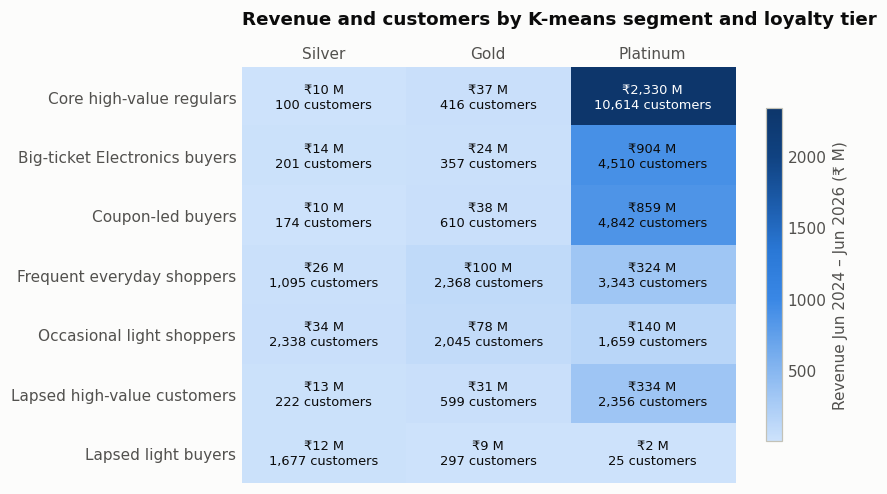

In [20]:
seg_order = SEGMENT_ORDER[::-1]
counts = tier_counts.loc[SEGMENT_ORDER, TIER_ORDER]
revenue = tier_revenue.loc[SEGMENT_ORDER, TIER_ORDER]

fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(revenue.values / 1e6, cmap=BLUES, aspect="auto")
ax.set_xticks(range(3), TIER_ORDER)
ax.set_yticks(range(len(SEGMENT_ORDER)), SEGMENT_ORDER)
ax.xaxis.tick_top()
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
vmax = revenue.values.max() / 1e6
for i in range(len(SEGMENT_ORDER)):
    for j in range(3):
        v = revenue.values[i, j] / 1e6
        ax.text(j, i, f"₹{v:,.0f} M\n{counts.values[i, j]:,} customers", ha="center", va="center", fontsize=8.5,
                color="white" if v > vmax * 0.55 else ps.TEXT_PRIMARY)
fig.colorbar(im, ax=ax, shrink=0.8, label="Revenue Jun 2024 – Jun 2026 (₹ M)")
ax.set_title("Revenue and customers by K-means segment and loyalty tier", loc="left", pad=28)
fig.tight_layout()
ps.save(fig, "nb04_tier_matrix")
plt.show()

**Findings:**

- **The charter's hypothesis holds: tier tracks spend, not recency.**
  - Tier correlates strongly with total spend (ρ = +0.764) and basket size (+0.695), moderately with order count (+0.396), and only weakly with recency (−0.126).
  - It is unrelated to coupon use (+0.023) and payment mode (−0.079).
  - Median spend is ₹12,498 (Silver), ₹39,572 (Gold) and ₹150,884 (Platinum). Median AOV is ₹3,207, ₹8,742 and ₹26,531.
- **K-means segments line up with tier more than RFM segments do** (Cramér's V 0.505 against 0.425). Both still leave much of the tier unexplained (adjusted Rand index 0.127 and 0.082).
- **Platinum dominates value:** 27,349 of 39,848 customers (68.6%) and ₹4,893.5 M of ₹5,328.1 M revenue (91.8%) over the 25 months. Within every segment, Platinum customers hold most of the revenue, apart from Lapsed light buyers, which are 83.9% Silver *[NB03]*.

### Under-tiered and over-tiered customers, tested against 2026

The charter defined two mismatch groups:

- **Under-tiered:** Silver or Gold customers in one of the three top-value segments (Core high-value regulars, Big-ticket Electronics buyers, Coupon-led buyers *[NB03]*). On past behaviour they look like the best customers.
- **Over-tiered (low-activity Platinum):** Platinum customers in one of the two lapsed segments, or with no order for longer than the 90th-percentile gap from Section 5. On past behaviour they look like they are slipping away.

Before turning these into lists, the same definitions are applied to the **calibration** segments (Dec 2025) and checked against Jan–Jun 2026. If past behaviour is the better guide, under-tiered customers should spend like Platinum customers in 2026, and low-activity Platinum customers should lapse more than other Platinum customers. If tier is the better guide, both groups should behave like the rest of their own tier.

In [21]:
TOP_SEGMENTS = ["Core high-value regulars", "Big-ticket Electronics buyers", "Coupon-led buyers"]
LAPSED_SEGMENTS = ["Lapsed high-value customers", "Lapsed light buyers"]


def mismatch_flags(t):
    tier = t.customer_tier.astype(str)
    under = tier.isin(["Silver", "Gold"]) & t.kmeans_segment.isin(TOP_SEGMENTS)
    over = (tier == "Platinum") & ((t.recency_days > GAP_THRESHOLD) | t.kmeans_segment.isin(LAPSED_SEGMENTS))
    return under, over


cal_under, cal_over = mismatch_flags(cal)
cal_tier = cal.customer_tier.astype(str)
test_groups = {
    "Under-tiered Silver": cal_under & (cal_tier == "Silver"),
    "Other Silver": ~cal_under & (cal_tier == "Silver"),
    "Under-tiered Gold": cal_under & (cal_tier == "Gold"),
    "Other Gold": ~cal_under & (cal_tier == "Gold"),
    "Platinum in the same top-value segments": (cal_tier == "Platinum") & cal.kmeans_segment.isin(TOP_SEGMENTS),
    "Low-activity Platinum": cal_over,
    "Other Platinum": ~cal_over & (cal_tier == "Platinum"),
}
tier_test = pd.DataFrame({name: {"customers": m.sum(),
                                 "calibration_spend_per_customer": cal.loc[m, "monetary"].mean(),
                                 "median_recency_dec_2025": cal.loc[m, "recency_days"].median(),
                                 "lapse_rate_2026": cal.loc[m, "lapsed"].mean(),
                                 "spend_per_customer_2026": cal.loc[m, "holdout_spend"].mean()}
                          for name, m in test_groups.items()}).T
tier_test.style.format({"customers": "{:,.0f}", "calibration_spend_per_customer": "₹{:,.0f}",
                        "median_recency_dec_2025": "{:,.0f}", "lapse_rate_2026": "{:.1%}",
                        "spend_per_customer_2026": "₹{:,.0f}"})

,customers,calibration_spend_per_customer,median_recency_dec_2025,lapse_rate_2026,spend_per_customer_2026
Under-tiered Silver,"1,162","₹27,420",111,37.7%,"₹5,420"
Other Silver,"4,424","₹13,124",117,35.5%,"₹4,558"
Under-tiered Gold,"1,827","₹51,508",88,30.8%,"₹9,910"
Other Gold,"4,777","₹30,524",94,24.1%,"₹11,381"
Platinum in the same top-value segments,"18,580","₹164,008",63,21.7%,"₹39,850"
Low-activity Platinum,"4,691","₹101,843",257,16.4%,"₹50,806"
Other Platinum,"22,550","₹143,950",58,20.1%,"₹40,746"


**Finding: both mismatch groups behaved like their own tier in 2026, not like the tier their past behaviour suggested.**

- **Under-tiered Silver** customers had spent twice as much as other Silver customers in 2024–25 (₹27,420 against ₹13,124). In Jan–Jun 2026 they spent ₹5,420 each, close to other Silver customers (₹4,558) and far below Platinum customers in the same segments (₹39,850). They also lapsed at a similar rate (37.7% against 35.5%).
- **Under-tiered Gold** customers did *worse* than other Gold customers: they lapsed at 30.8% (against 24.1%) and spent ₹9,910 (against ₹11,381).
- **Low-activity Platinum** customers (median 257 days since last order) did *better* than other Platinum customers: they lapsed at 16.4% (against 20.1%) and spent ₹50,806 each (against ₹40,746). They came back without any intervention.

**Answer to the executive question, "Is our tier programme rewarding the right people?":** on this evidence, yes. Tier is a better guide to a customer's next six months than their recent behaviour. Upgrading customers on past behaviour would not have been backed by their later spending, and a win-back campaign aimed at quiet Platinum customers would have spent money on customers who were about to return anyway.

**Caveat:** tier is assigned partly on spend *[First project README]*, and the exact rules are not given. Tier may therefore hold information about long-run spending that the behavioural features, built on a 19-month window, do not capture.

### The two lists, as at 30 Jun 2026

The same definitions are applied to the current segments. Given the test above, the lists are **candidates for a controlled trial**, not for an immediate tier change: the business would upgrade or contact a random half of each list and compare the two halves. Revenue is valid-order spend over the full 25 months; the six-month value scales it by 6/25.

In [22]:
FULL_MONTHS = 25
current["six_month_spend"] = current.monetary * 6 / FULL_MONTHS

under_now, over_now = mismatch_flags(current)
under, over = current[under_now], current[over_now]


def group_summary(g):
    return pd.Series({"customers": len(g), "share_of_tier_base": np.nan, "revenue": g.monetary.sum(),
                      "six_month_value": g.six_month_spend.sum(), "median_aov": g.aov.median(),
                      "median_recency_days": g.recency_days.median()})


mismatch = pd.DataFrame({"Under-tiered (Silver/Gold in top-value segments)": group_summary(under),
                         "Low-activity Platinum": group_summary(over)}).T
mismatch["share_of_tier_base"] = [len(under) / current.customer_tier.isin(["Silver", "Gold"]).sum(),
                                  len(over) / (current.customer_tier == "Platinum").sum()]
display(mismatch.style.format({"customers": "{:,.0f}", "share_of_tier_base": "{:.1%}",
                               "revenue": lambda v: f"₹{v / 1e6:,.1f} M", "six_month_value": lambda v: f"₹{v / 1e6:,.1f} M",
                               "median_aov": "₹{:,.0f}", "median_recency_days": "{:,.0f}"}))
display(pd.crosstab(under.kmeans_segment, under.customer_tier).loc[TOP_SEGMENTS, ["Silver", "Gold"]].style.format("{:,.0f}"))
display(over.groupby("kmeans_segment", observed=True).agg(customers=("monetary", "size"),
        median_recency_days=("recency_days", "median")).style.format("{:,.0f}"))

,customers,share_of_tier_base,revenue,six_month_value,median_aov,median_recency_days
Under-tiered (Silver/Gold in top-value segments),"1,858",14.9%,₹132.5 M,₹31.8 M,"₹14,328",84
Low-activity Platinum,"4,058",14.8%,₹632.0 M,₹151.7 M,"₹30,304",279


customer_tier,Silver,Gold
kmeans_segment,,
Core high-value regulars,100,416
Big-ticket Electronics buyers,201,357
Coupon-led buyers,174,610


,customers,median_recency_days
kmeans_segment,,
Core high-value regulars,359,227
Big-ticket Electronics buyers,610,251
Coupon-led buyers,388,241
Frequent everyday shoppers,200,242
Occasional light shoppers,120,238
Lapsed high-value customers,"2,356",322
Lapsed light buyers,25,281


**The current lists (30 Jun 2026):**

| List | Customers | Share of tier base | Revenue (25 months) | Six-month value |
|---|---|---|---|---|
| Under-tiered (Silver/Gold in top-value segments) | 1,858 | 14.9% of Silver and Gold | ₹132.5 M | ₹31.8 M |
| Low-activity Platinum | 4,058 | 14.8% of Platinum | ₹632.0 M | ₹151.7 M |

Most low-activity Platinum customers (2,356) are in Lapsed high-value customers, with a median of 279 days since their last order.

**Recommendation:** treat both lists as **trial groups**, not as decisions. For example:

- offer an upgrade incentive to a random half of the under-tiered list and compare their spend with the other half over six months;
- contact half of the low-activity Platinum list and compare return rates.

The holdout test suggests neither action will beat doing nothing, and a trial is a cheap way to confirm that before committing budget.

## 8. Looking ahead: Jul–Dec 2026

The forward look uses the score that did best in Section 4: **loyalty tier × K-means segment** (21 groups). Each customer's **expected lapse probability** is the Jan–Jun 2026 lapse rate of their tier-and-segment group, applied to their tier and segment at 30 Jun 2026. The **expected revenue at risk** is that probability × the customer's six-month spend at their 25-month pace.

The win-back list ranks customers by expected revenue at risk and keeps those who together account for **half** of it, so the list stays a manageable size while covering most of the value.

This is an estimate. It assumes Jul–Dec 2026 behaves like Jan–Jun 2026. The first project found monthly revenue flat over two years with no clear seasonal peak *[Report §3.1]*, which supports carrying the rates forward, but the figures remain a planning guide, not a forecast.

In [23]:
cell_rates = cal.groupby([cal.customer_tier.astype(str), cal.kmeans_segment.astype(str)]).lapsed.agg(["mean", "size"])
print(f"Tier × segment groups: {len(cell_rates)}, smallest {cell_rates['size'].min():,} customers")

keys = pd.MultiIndex.from_arrays([current.customer_tier.astype(str), current.kmeans_segment.astype(str)])
current["lapse_probability"] = cell_rates["mean"].reindex(keys).fillna(BASE_LAPSE).to_numpy()
current["expected_revenue_at_risk"] = current.lapse_probability * current.six_month_spend


def outlook_by(by):
    o = current.groupby(by, observed=True).agg(
        customers=("monetary", "size"), expected_lapsers=("lapse_probability", "sum"),
        six_month_value=("six_month_spend", "sum"), expected_revenue_at_risk=("expected_revenue_at_risk", "sum"))
    o.loc["All customers"] = o.sum(numeric_only=True)
    o["expected_lapse_rate"] = o.expected_lapsers / o.customers
    o["share_of_risk"] = o.expected_revenue_at_risk / o.loc["All customers", "expected_revenue_at_risk"]
    return o


OUTLOOK_FORMAT = {"customers": "{:,.0f}", "expected_lapsers": "{:,.0f}", "six_month_value": lambda v: f"₹{v / 1e6:,.1f} M",
                  "expected_revenue_at_risk": lambda v: f"₹{v / 1e6:,.1f} M", "expected_lapse_rate": "{:.1%}",
                  "share_of_risk": "{:.1%}"}
display(outlook_by("customer_tier").style.format(OUTLOOK_FORMAT))
display(outlook_by("kmeans_segment").style.format(OUTLOOK_FORMAT))

Tier × segment groups: 21, smallest 111 customers


,customers,expected_lapsers,six_month_value,expected_revenue_at_risk,expected_lapse_rate,share_of_risk
customer_tier,,,,,,
Silver,"5,807","2,089",₹28.6 M,₹10.8 M,36.0%,4.1%
Gold,"6,692","1,770",₹75.7 M,₹20.8 M,26.4%,8.0%
Platinum,"27,349","5,132","₹1,174.4 M",₹229.6 M,18.8%,87.9%
All customers,"39,848","8,991","₹1,278.8 M",₹261.2 M,22.6%,100.0%


,customers,expected_lapsers,six_month_value,expected_revenue_at_risk,expected_lapse_rate,share_of_risk
kmeans_segment,,,,,,
Core high-value regulars,"11,130","2,589",₹570.7 M,₹130.5 M,23.3%,50.0%
Big-ticket Electronics buyers,"5,068","1,195",₹226.0 M,₹51.1 M,23.6%,19.6%
Coupon-led buyers,"5,626",758,₹217.7 M,₹26.4 M,13.5%,10.1%
Frequent everyday shoppers,"6,806","1,544",₹107.8 M,₹21.2 M,22.7%,8.1%
Occasional light shoppers,"6,042","1,529",₹60.6 M,₹11.1 M,25.3%,4.2%
Lapsed high-value customers,"3,177",764,₹90.7 M,₹19.5 M,24.1%,7.5%
Lapsed light buyers,"1,999",611,₹5.3 M,₹1.3 M,30.6%,0.5%
All customers,"39,848","8,991","₹1,278.8 M",₹261.2 M,22.6%,100.0%


In [24]:
# Win-back list: customers ranked by expected revenue at risk, down to half of the total
ranked = current.sort_values("expected_revenue_at_risk", ascending=False).copy()
cumulative_share = ranked.expected_revenue_at_risk.cumsum() / ranked.expected_revenue_at_risk.sum()
winback = ranked[cumulative_share.shift(fill_value=0) < 0.5].copy()
winback.insert(0, "rank", range(1, len(winback) + 1))
print(f"Customers covering half of the expected revenue at risk: {len(winback):,} of {len(current):,} "
      f"({len(winback) / len(current):.1%}), ₹{winback.expected_revenue_at_risk.sum() / 1e6:,.1f} M")
display(pd.crosstab(winback.kmeans_segment, pd.Categorical(winback.customer_tier, categories=TIER_ORDER),
                    margins=True, margins_name="All", dropna=False).rename_axis(columns="customer_tier"))
winback.head(10)[["rank", "kmeans_segment", "rfm_segment", "customer_tier", "recency_days", "frequency", "aov",
                  "lapse_probability", "expected_revenue_at_risk"]].style.format(
    {"recency_days": "{:,.0f}", "frequency": "{:,.0f}", "aov": "₹{:,.0f}", "lapse_probability": "{:.1%}",
     "expected_revenue_at_risk": "₹{:,.0f}"})

Customers covering half of the expected revenue at risk: 8,054 of 39,848 (20.2%), ₹130.6 M


customer_tier,Silver,Gold,Platinum,All
kmeans_segment,,,,
Core high-value regulars,41,89,5374,5504
Big-ticket Electronics buyers,37,39,1848,1924
Coupon-led buyers,17,19,184,220
Frequent everyday shoppers,6,1,13,20
Occasional light shoppers,1,0,0,1
Lapsed high-value customers,38,28,319,385
Lapsed light buyers,0,0,0,0
All,140,176,7738,8054


,rank,kmeans_segment,rfm_segment,customer_tier,recency_days,frequency,aov,lapse_probability,expected_revenue_at_risk
customer_id,,,,,,,,,
CUST00004600,1,Core high-value regulars,Champions,Platinum,43,9,"₹98,904",22.6%,"₹48,232"
CUST00018065,2,Big-ticket Electronics buyers,Champions,Platinum,61,7,"₹129,545",22.1%,"₹48,049"
CUST00021066,3,Core high-value regulars,Champions,Platinum,3,13,"₹67,456",22.6%,"₹47,517"
CUST00017168,4,Big-ticket Electronics buyers,Champions,Platinum,26,9,"₹98,818",22.1%,"₹47,124"
CUST00003487,5,Core high-value regulars,At risk,Platinum,124,11,"₹79,037",22.6%,"₹47,109"
CUST00020280,6,Big-ticket Electronics buyers,Champions,Platinum,19,7,"₹125,414",22.1%,"₹46,517"
CUST00009202,7,Core high-value regulars,At risk,Platinum,120,12,"₹70,294",22.6%,"₹45,707"
CUST00021754,8,Core high-value regulars,Champions,Platinum,39,12,"₹69,497",22.6%,"₹45,189"
CUST00020290,9,Core high-value regulars,Champions,Platinum,16,17,"₹47,247",22.6%,"₹43,521"


**Findings (estimate for Jul–Dec 2026):**

- **8,991 customers (22.6%) are expected to place no order, taking an expected ₹261.2 M** of six-month spend with them.
- **Platinum holds 87.9% of the expected loss**, despite having the lowest expected lapse rate (18.8% against 36.0% for Silver), because Platinum customers spend far more.
- **By segment:** Core high-value regulars account for 50.0% of the expected loss, Big-ticket Electronics buyers 19.6% and Coupon-led buyers 10.1%.
- **The win-back list:** 8,054 customers (20.2% of the base) account for half the expected loss (₹130.6 M). Of these, 7,738 are Platinum, and most are Core high-value regulars (5,504) or Big-ticket Electronics buyers (1,924). Many are recent, active buyers: eight of the ten highest-ranked are RFM Champions or Loyal.

**Implication:** because expected lapse rates vary only from 2.6% to 43.7% while spend varies more than 100-fold, the ranking is driven mainly by spend. In practice, this is a **list of the customers whose loss would cost most**, not of customers who are leaving. The playbook should treat it as a *retention-protection* list (service quality, early access, recognition) rather than a *rescue* list (discounts to bring customers back).

## 9. Save the outputs

| File | Contents | Used by |
|---|---|---|
| `holdout_outcomes_calibration.csv` | Each calibration customer's Dec 2025 segments and Recency score, whether they lapsed, and their Jan–Jun 2026 spend | Notebook 5 (coupon users vs non-users, within segment) |
| `winback_ranked.csv` | Customers covering half of the expected revenue at risk, ranked | Playbook |
| `tier_upgrade_candidates.csv` | The under-tiered customers (trial candidates) | Playbook |
| `platinum_low_activity.csv` | The low-activity Platinum customers, highest spend first (trial candidates) | Playbook |

In [25]:
LIST_COLUMNS = ["customer_tier", "kmeans_segment", "rfm_segment", "r_score", "recency_days", "frequency", "aov", "monetary"]
outputs = {
    "holdout_outcomes_calibration.csv": cal[["kmeans_segment", "rfm_segment", "r_score", "recency_days", "coupon_rate",
                                             "customer_tier", "lapsed", "holdout_spend", "six_month_spend"]],
    "winback_ranked.csv": winback[["rank"] + LIST_COLUMNS + ["lapse_probability", "expected_revenue_at_risk"]],
    "tier_upgrade_candidates.csv": under.sort_values("monetary", ascending=False)[LIST_COLUMNS],
    "platinum_low_activity.csv": over.sort_values("monetary", ascending=False)[LIST_COLUMNS],
}
for name, table in outputs.items():
    table.to_csv(OUTPUT_DIR / name)
    print(f"Saved 01_data/output/{name}  ({len(table):,} rows, {(OUTPUT_DIR / name).stat().st_size / 1e3:,.0f} KB)")

Saved 01_data/output/holdout_outcomes_calibration.csv  (39,431 rows, 4,130 KB)
Saved 01_data/output/winback_ranked.csv  (8,054 rows, 1,073 KB)
Saved 01_data/output/tier_upgrade_candidates.csv  (1,858 rows, 161 KB)
Saved 01_data/output/platinum_low_activity.csv  (4,058 rows, 379 KB)


## 10. Summary

| Question | Answer *[Notebook 4]* |
|---|---|
| Do the segments reappear on 2024–25 data alone? | Yes. All seven names reappear, and the calibration model is stable (mean ARI 0.910) |
| Which segments lapsed most in Jan–Jun 2026? | None stand out. Every K-means and RFM segment lapsed at 22%–24% |
| Which method predicts lapse best? | Tier × K-means segment (AUC 0.606), then tier alone (0.570). Recency, RFM and K-means alone score about 0.50, no better than chance |
| Why? | Past orders and spend do not carry forward (ρ = +0.002), and within a tier they reverse. The overall lapse rate matches random ordering (22.7% expected against 22.9% observed). This is consistent with the first project's note that the data is likely synthetic |
| How long a gap signals a lapse? | None does. Normal gaps reach 209 days at the 90th percentile, but customers past that point lapse no more often (22.0% against 23.1%) |
| Does value build with tenure? | No. Spend per registered customer is flat across cohorts and over time (median ρ +0.04) |
| Do tiers match behaviour? | Tier tracks spend (ρ = +0.764) but not recency (−0.126). Customers whose behaviour does not match their tier behaved like their tier in 2026 |
| How much revenue is at risk in Jul–Dec 2026? | An expected ₹261.2 M, 87.9% of it from Platinum customers. 8,054 customers account for half |

### What this changes for the rest of the project

- **The charter's Objective 3 hypothesis is rejected.** Low Recency or falling Frequency did not identify the customers who stopped buying. The finding is reported as it stands, with the evidence for why.
- **The playbook (Notebook 6) will use each input for what it was shown to do:**
  - **tier** sets risk and priority;
  - the **K-means segment** sets the message and offer (what the customer buys, how they pay, whether they respond to coupons);
  - **recency** is not used as a trigger.
- **Notebook 5** will compare coupon users with non-users *within tier*, because tier is the main driver of lapse and spend found here.